In [ ]:
# MANUAL EXPLORATORY DATA ANALYSIS (EDA) USING PANDAS & MATPLOTLIB 

# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
# 2. Load Dataset


df = pd.read_csv("country_platform_summary_2025.csv")

print("=" * 60)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)

DATASET LOADED SUCCESSFULLY


In [ ]:
# 3. BASIC DATASET UNDERSTANDING


# Display first 5 records
print("\nFirst 5 Records:")
print(df.head())

# Display last 5 records
print("\nLast 5 Records:")
print(df.tail())

# Display random 5 records
print("\nRandom 5 Records:")
print(df.sample(5))

# Number of rows and columns
print("\nDataset Shape:")
print(df.shape)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Data types
print("\nData Types:")
print(df.dtypes)



First 5 Records:
  country platform  total_videos  total_views  median_er  p95_views  \
0      AE   TikTok          1017    102064271     0.0900  325484.40   
1      AE  YouTube           641     67638733     0.0492  332142.00   
2      AR   TikTok          1032    103715112     0.0877  311367.55   
3      AR  YouTube           629     57036717     0.0491  271985.20   
4      AU   TikTok           959     96885399     0.0898  306511.80   

   avg_duration  avg_velocity  avg_comment_ratio  avg_share_rate  \
0       29.7335    13785.7142             0.0077          0.0068   
1       41.8721    14381.0054             0.0043          0.0038   
2       29.7025    13126.5611             0.0076          0.0067   
3       40.7886    12136.0476             0.0042          0.0037   
4       29.7404    14376.2279             0.0077          0.0068   

   avg_save_rate  avg_engagement_per_1k top_hashtag  top_hashtag_views  
0         0.0072                92.4015        #FYP           26292844  


In [ ]:
# 4. STATISTICAL SUMMARY


print("\nNumerical Statistical Summary:")
print(df.describe())

print("\nStatistical Summary Including Categorical Columns:")
print(df.describe(include="all"))



Numerical Statistical Summary:
       total_videos   total_views  median_er      p95_views  avg_duration  \
count     60.000000  6.000000e+01  60.000000      60.000000     60.000000   
mean     828.400000  8.225318e+07   0.068970  310649.811667     35.557690   
std      170.134961  1.770085e+07   0.020077   23746.423466      5.385776   
min      622.000000  5.665754e+07   0.048000  255072.800000     29.640600   
25%      657.250000  6.514869e+07   0.049100  298718.050000     30.145300   
50%      822.500000  8.203921e+07   0.068100  311743.475000     35.595050   
75%      989.000000  9.937930e+07   0.088800  323451.062500     40.790300   
max     1068.000000  1.078324e+08   0.090800  374575.200000     41.960800   

       avg_velocity  avg_comment_ratio  avg_share_rate  avg_save_rate  \
count     60.000000          60.000000       60.000000      60.000000   
mean   13834.463982           0.005967        0.005258       0.005620   
std      877.161095           0.001740        0.001529 

In [37]:
# 5. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS


numerical_columns = df.select_dtypes(
    include=np.number
).columns

categorical_columns = df.select_dtypes(
    include="object"
).columns

print("\nNumerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))


Numerical Columns:
['total_videos', 'total_views', 'median_er', 'p95_views', 'avg_duration', 'avg_velocity', 'avg_comment_ratio', 'avg_share_rate', 'avg_save_rate', 'avg_engagement_per_1k', 'top_hashtag_views']

Categorical Columns:
['country', 'platform', 'top_hashtag']


In [38]:
# 6. CHECK MISSING VALUES


print("\nMissing Values in Each Column:")
print(df.isnull().sum())

# Missing percentage
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("\nMissing Value Percentage:")
print(missing_percentage)

# Display columns having missing values
print("\nColumns Having Missing Values:")
print(
    missing_percentage[
        missing_percentage > 0
    ]
)


Missing Values in Each Column:
country                  0
platform                 0
total_videos             0
total_views              0
median_er                0
p95_views                0
avg_duration             0
avg_velocity             0
avg_comment_ratio        0
avg_share_rate           0
avg_save_rate            0
avg_engagement_per_1k    0
top_hashtag              0
top_hashtag_views        0
dtype: int64

Missing Value Percentage:
country                  0.0
platform                 0.0
total_videos             0.0
total_views              0.0
median_er                0.0
p95_views                0.0
avg_duration             0.0
avg_velocity             0.0
avg_comment_ratio        0.0
avg_share_rate           0.0
avg_save_rate            0.0
avg_engagement_per_1k    0.0
top_hashtag              0.0
top_hashtag_views        0.0
dtype: float64

Columns Having Missing Values:
Series([], dtype: float64)


In [39]:
# 7. HANDLE MISSING VALUES


# Numerical columns → fill with median
for column in numerical_columns:

    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(
            df[column].median()
        )


# Categorical columns → fill with mode
for column in categorical_columns:

    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )


print("\nMissing Values After Treatment:")
print(df.isnull().sum())


Missing Values After Treatment:
country                  0
platform                 0
total_videos             0
total_views              0
median_er                0
p95_views                0
avg_duration             0
avg_velocity             0
avg_comment_ratio        0
avg_share_rate           0
avg_save_rate            0
avg_engagement_per_1k    0
top_hashtag              0
top_hashtag_views        0
dtype: int64


In [40]:
# 8. CHECK DUPLICATE RECORDS

duplicate_count = df.duplicated().sum()

print("\nNumber of Duplicate Rows:")
print(duplicate_count)

# Remove duplicates
df = df.drop_duplicates()

print("Shape After Removing Duplicates:")
print(df.shape)


# 9. UNIQUE VALUES

print("\nNumber of Unique Values in Each Column:")

for column in df.columns:

    print(
        column,
        "→",
        df[column].nunique()
    )


Number of Duplicate Rows:
0
Shape After Removing Duplicates:
(60, 14)

Number of Unique Values in Each Column:
country → 30
platform → 2
total_videos → 54
total_views → 60
median_er → 35
p95_views → 60
avg_duration → 60
avg_velocity → 60
avg_comment_ratio → 9
avg_share_rate → 6
avg_save_rate → 9
avg_engagement_per_1k → 60
top_hashtag → 1
top_hashtag_views → 60


In [41]:
# 10. VALUE COUNTS FOR CATEGORICAL DATA

for column in categorical_columns:

    print("\n" + "=" * 50)
    print("Value Counts:", column)
    print("=" * 50)

    print(df[column].value_counts().head(10))


Value Counts: country
country
AE    2
AR    2
US    2
TR    2
SE    2
SA    2
RU    2
PL    2
PH    2
NL    2
Name: count, dtype: int64

Value Counts: platform
platform
TikTok     30
YouTube    30
Name: count, dtype: int64

Value Counts: top_hashtag
top_hashtag
#FYP    60
Name: count, dtype: int64


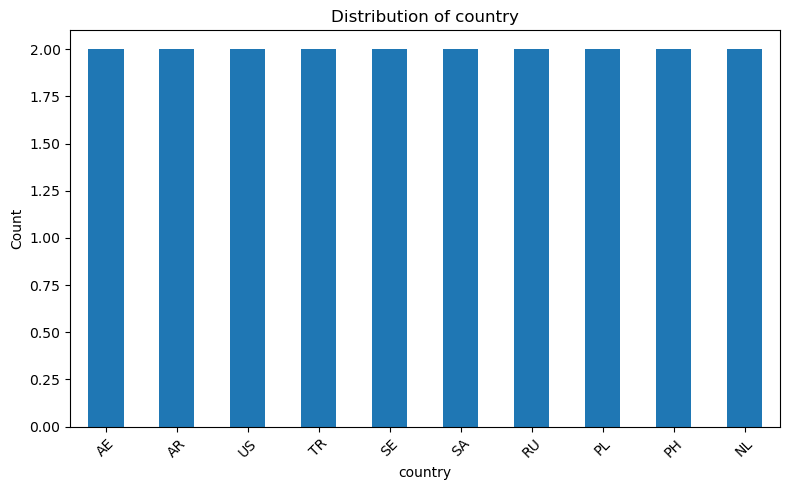

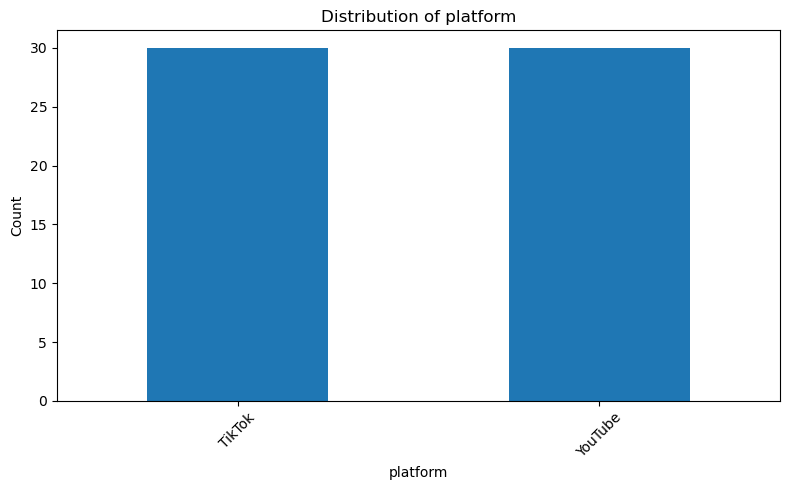

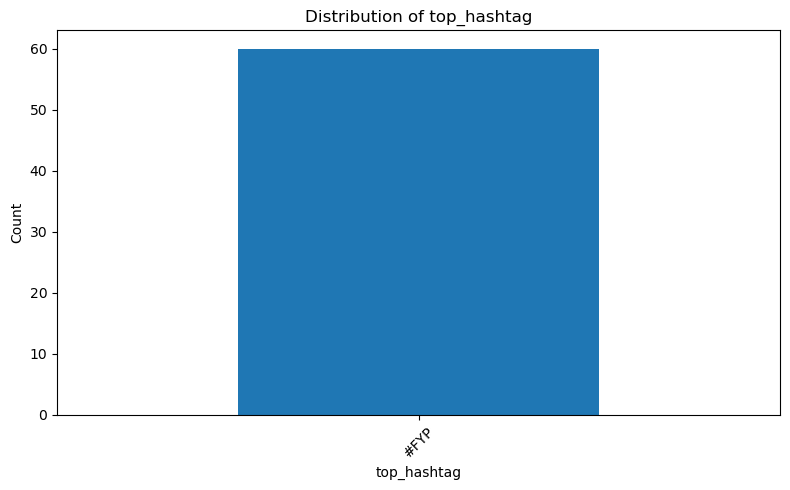

In [42]:
# 11. BAR CHART FOR CATEGORICAL VARIABLES

for column in categorical_columns:

    # Display only top 10 categories
    value_counts = df[column].value_counts().head(10)

    plt.figure(figsize=(8, 5))

    value_counts.plot(kind="bar")

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Count")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

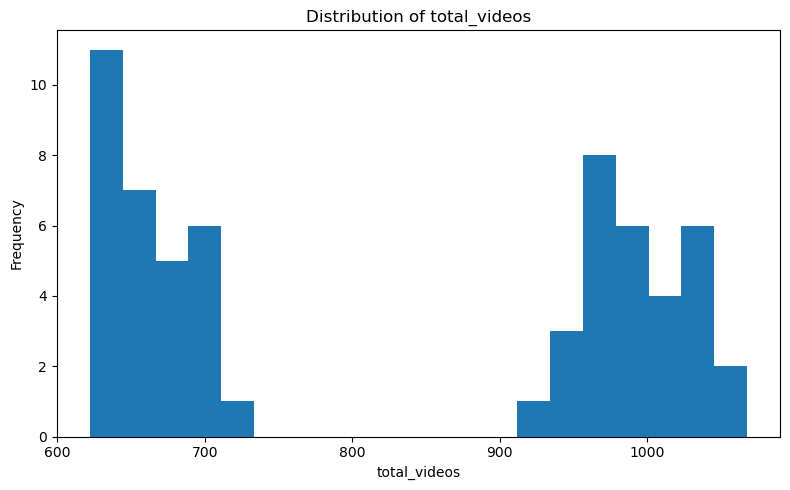

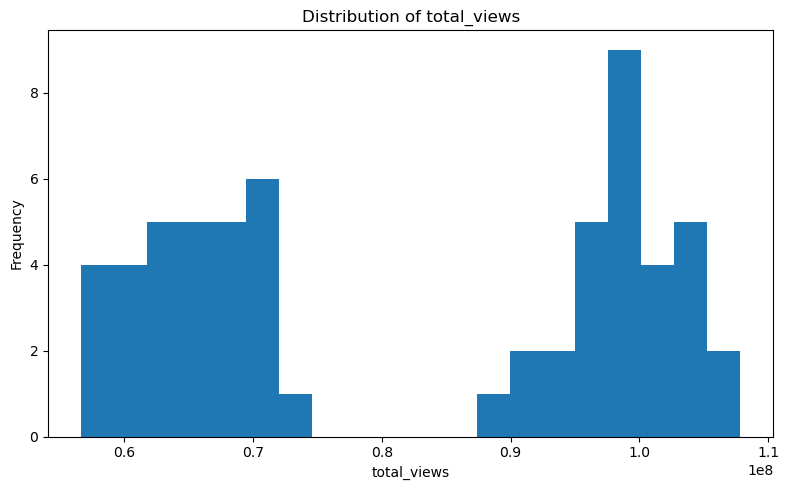

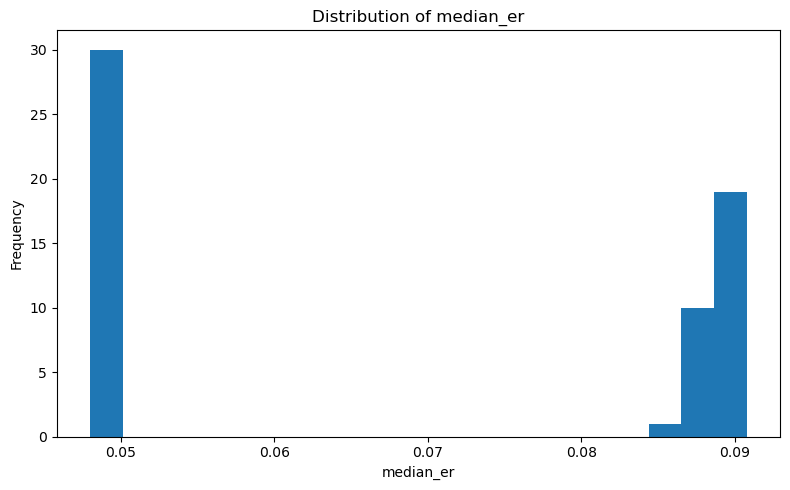

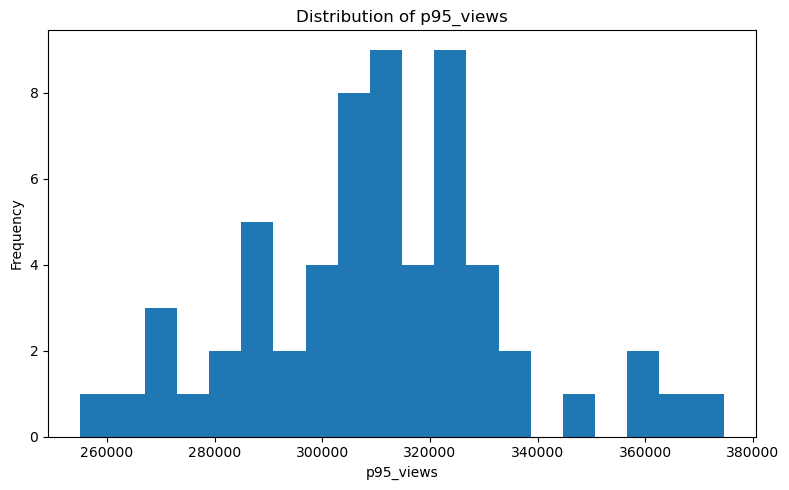

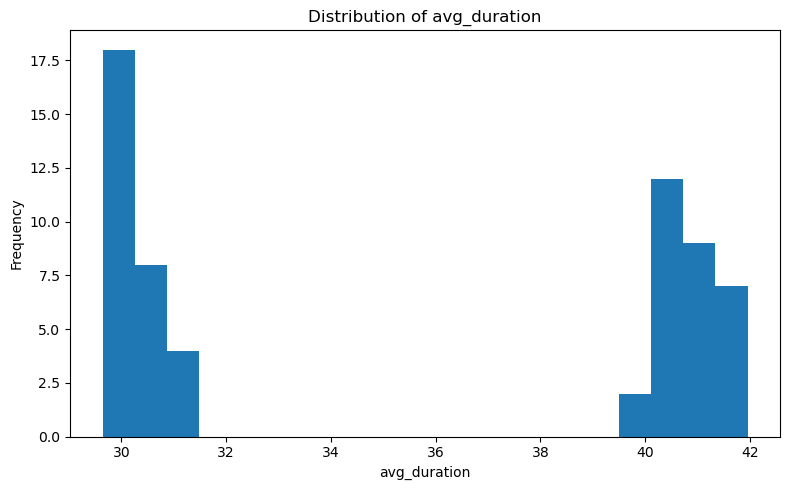

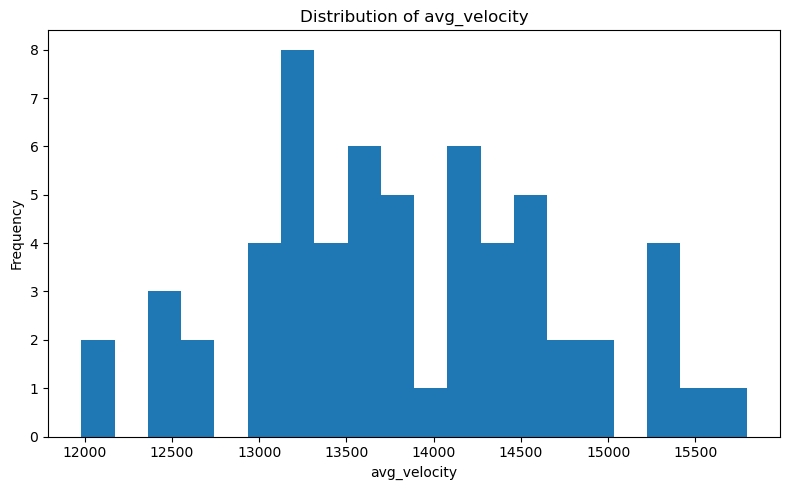

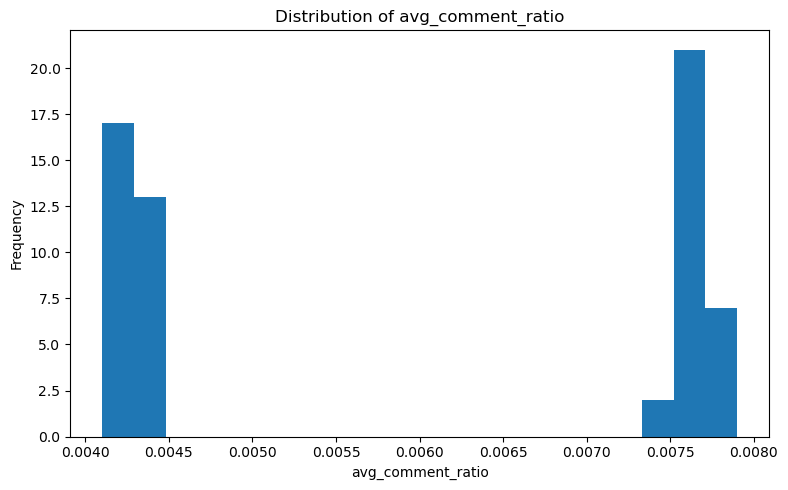

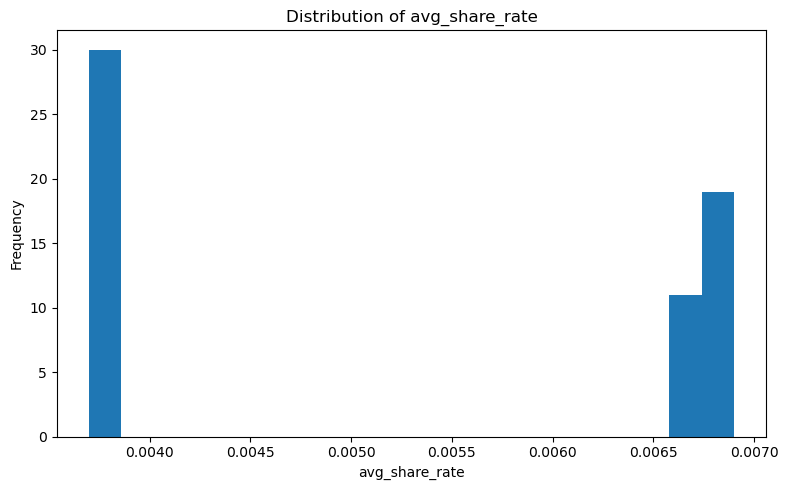

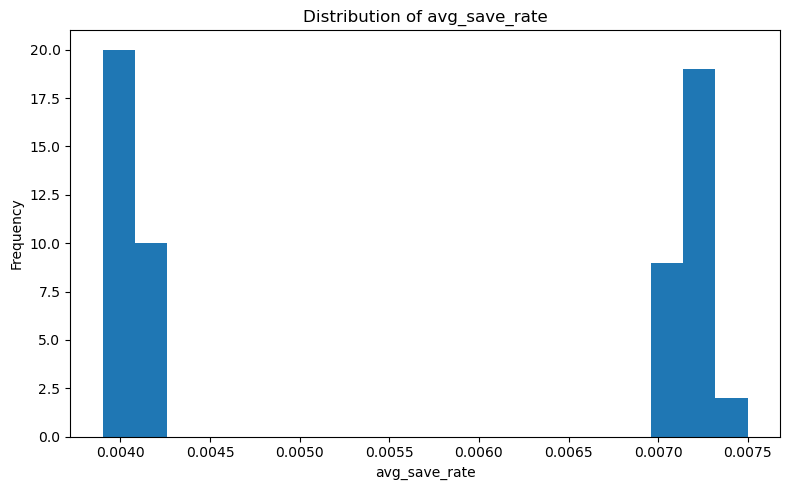

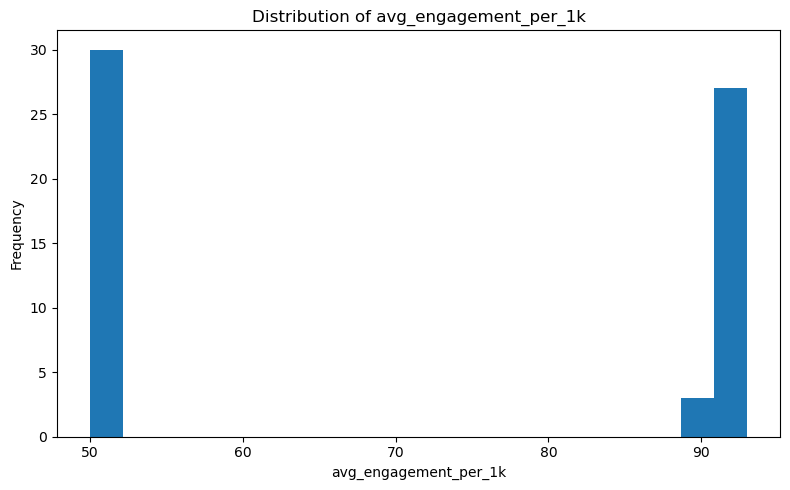

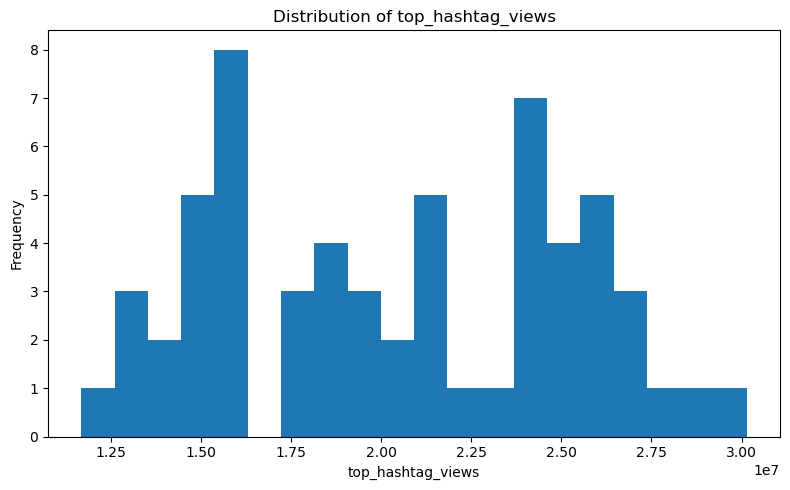

In [43]:
# 12. HISTOGRAM FOR NUMERICAL VARIABLES

for column in numerical_columns:

    plt.figure(figsize=(8, 5))

    plt.hist(
        df[column],
        bins=20
    )

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

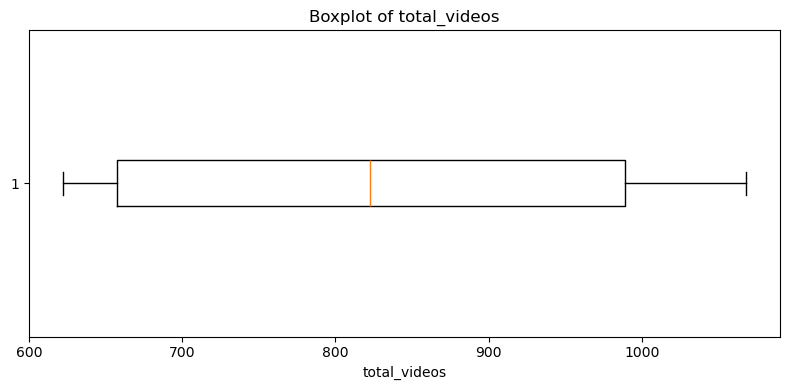

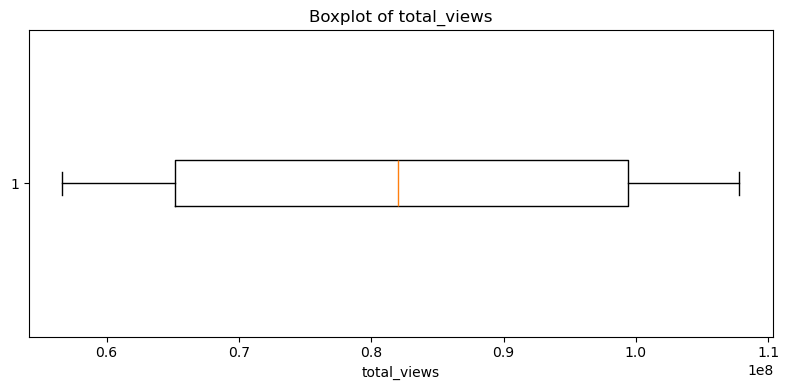

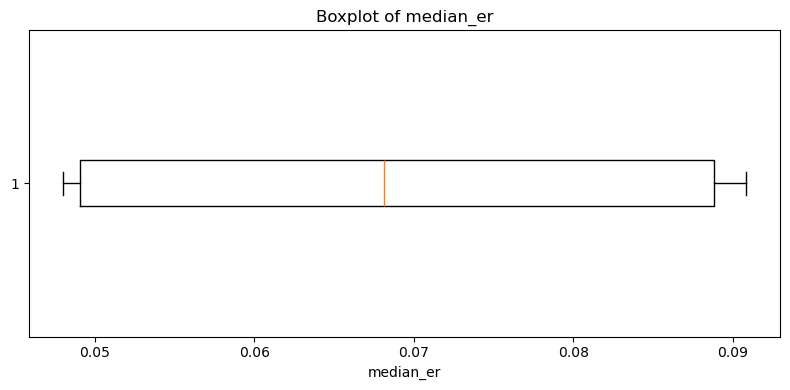

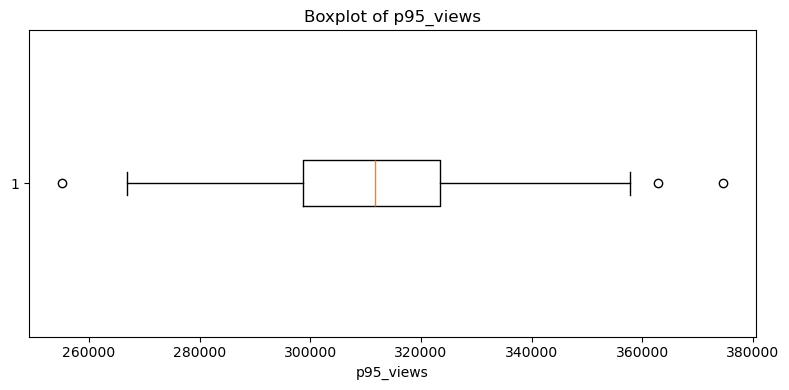

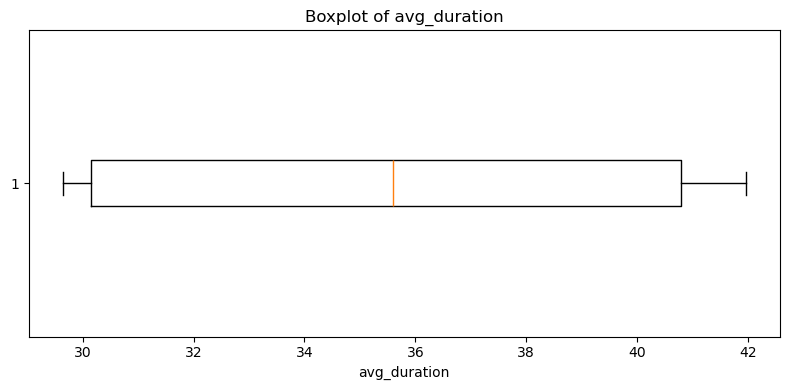

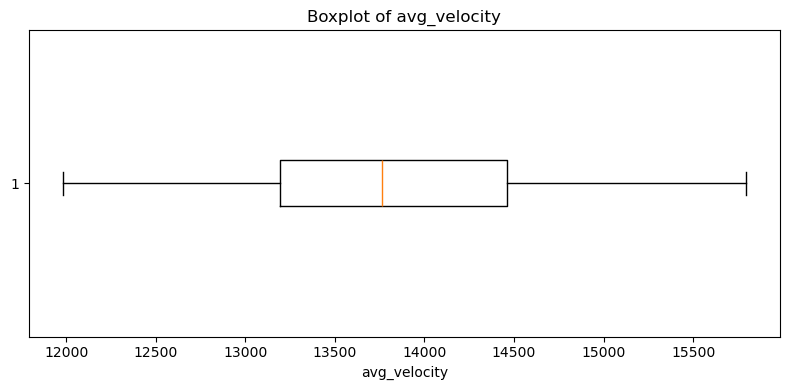

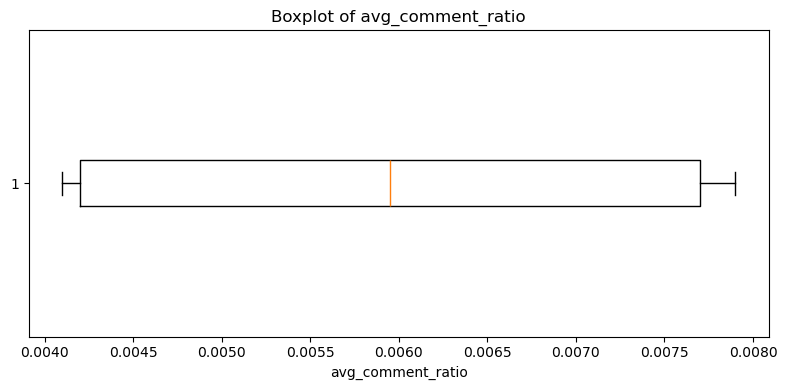

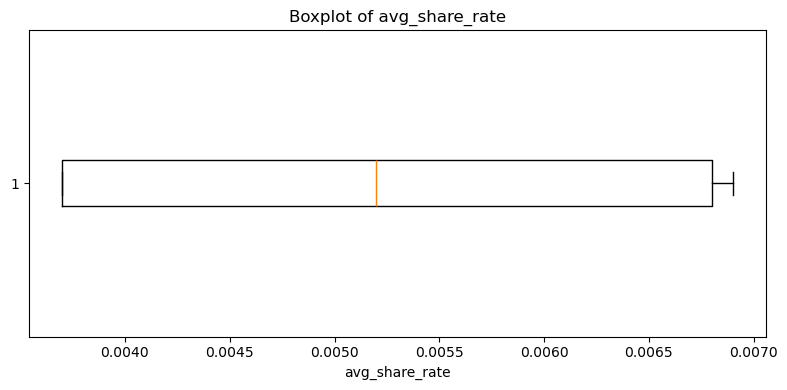

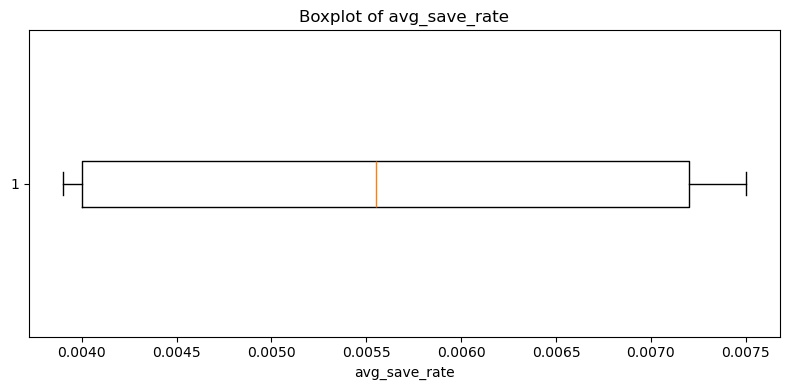

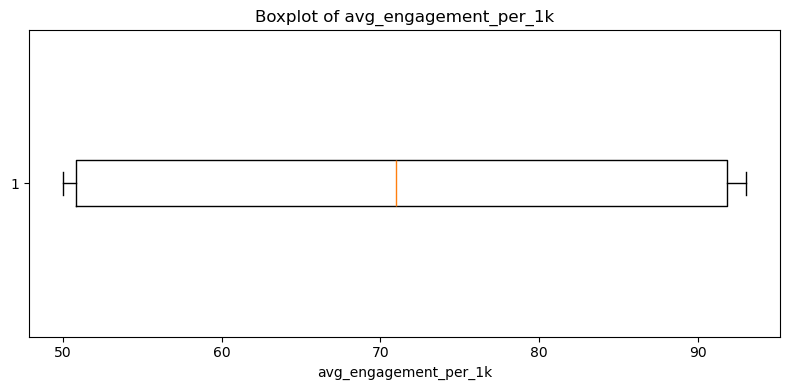

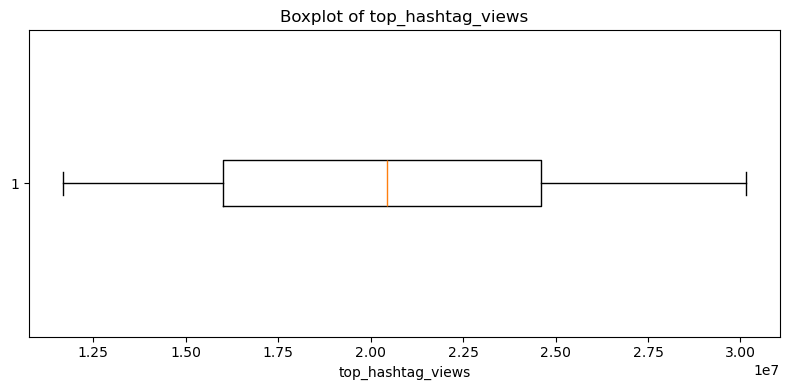

In [44]:
# 13. BOXPLOT – OUTLIER DETECTION

for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    plt.boxplot(
        df[column].dropna(),
        vert=False
    )

    plt.title("Boxplot of " + column)
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

In [45]:
# 14. OUTLIER DETECTION USING IQR

print("\n" + "=" * 60)
print("OUTLIER ANALYSIS")
print("=" * 60)

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("\nColumn:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


OUTLIER ANALYSIS

Column: total_videos
Q1: 657.25
Q3: 989.0
IQR: 331.75
Lower Limit: 159.625
Upper Limit: 1486.625
Number of Outliers: 0

Column: total_views
Q1: 65148685.25
Q3: 99379295.75
IQR: 34230610.5
Lower Limit: 13802769.5
Upper Limit: 150725211.5
Number of Outliers: 0

Column: median_er
Q1: 0.0491
Q3: 0.0888
IQR: 0.039700000000000006
Lower Limit: -0.010450000000000008
Upper Limit: 0.14835
Number of Outliers: 0

Column: p95_views
Q1: 298718.05
Q3: 323451.0624999998
IQR: 24733.012499999837
Lower Limit: 261618.53125000023
Upper Limit: 360550.5812499996
Number of Outliers: 3

Column: avg_duration
Q1: 30.1453
Q3: 40.7903
IQR: 10.645000000000003
Lower Limit: 14.177799999999994
Upper Limit: 56.7578
Number of Outliers: 0

Column: avg_velocity
Q1: 13195.56905
Q3: 14460.7207
IQR: 1265.1516499999998
Lower Limit: 11297.841575
Upper Limit: 16358.448175
Number of Outliers: 0

Column: avg_comment_ratio
Q1: 0.0042
Q3: 0.0077
IQR: 0.0035000000000000005
Lower Limit: -0.0010500000000000015
Upper


Correlation Matrix:
                       total_videos  total_views  median_er  p95_views  \
total_videos               1.000000     0.981014   0.980705   0.178753   
total_views                0.981014     1.000000   0.961991   0.303090   
median_er                  0.980705     0.961991   1.000000   0.171179   
p95_views                  0.178753     0.303090   0.171179   1.000000   
avg_duration              -0.975994    -0.956795  -0.995074  -0.159176   
avg_velocity               0.332366     0.462396   0.308281   0.609020   
avg_comment_ratio          0.981544     0.963951   0.999288   0.181766   
avg_share_rate             0.980483     0.963644   0.999204   0.177139   
avg_save_rate              0.981257     0.963523   0.998585   0.171707   
avg_engagement_per_1k      0.981972     0.964174   0.999710   0.174921   
top_hashtag_views          0.869157     0.898068   0.834023   0.252969   

                       avg_duration  avg_velocity  avg_comment_ratio  \
total_videos      

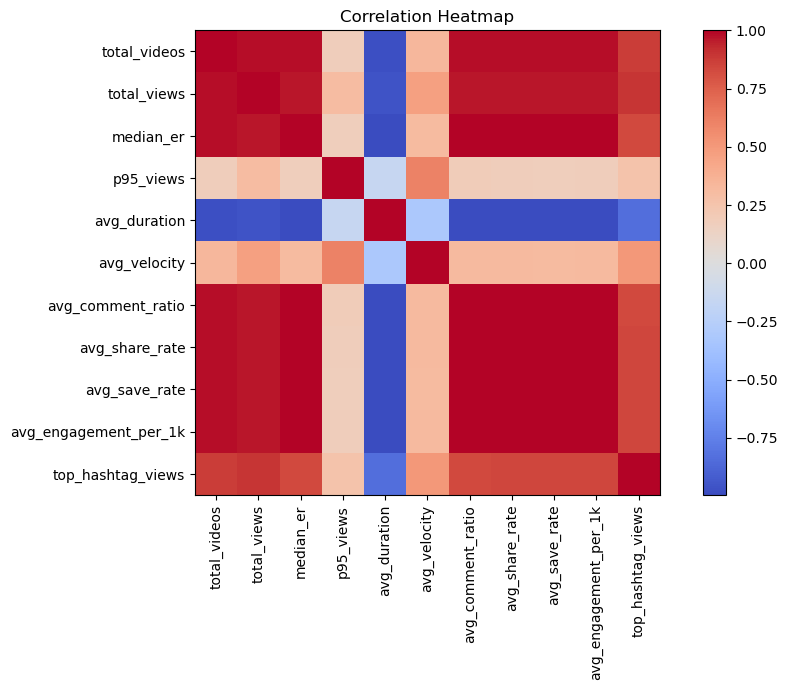

In [46]:
# 15. CORRELATION ANALYSIS

correlation = df[
    numerical_columns
].corr()

print("\nCorrelation Matrix:")
print(correlation)


# 16. CORRELATION HEATMAP

plt.figure(figsize=(10, 7))

plt.imshow(
    correlation,
    cmap="coolwarm",
    interpolation="nearest"
)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()
